# Multi-Class Classification with Hidden Layers

Open in [Google Colab](https://colab.research.google.com/github/febse/ta2025/blob/main/03-06-ANN-Multiclass-Classification.ipynb)

In the [previous chapter](03-05-ANN-Logistic-Regression.ipynb) we built a network with a hidden layer for two classes: a sigmoid output and the binary cross-entropy loss. Many classification problems have more than two classes (nationality, type of disease, species of an animal, credit risk level: low/medium/high, or the next word in a text). In this chapter we generalize the network to $K$ classes. The output layer gets $K$ neurons, the sigmoid is replaced by the **softmax** function, and the loss is the cross-entropy loss (see the previous chapter for its definition and for its relation to the likelihood). We state the network in matrix notation, summarize the gradients needed for gradient descent (their derivation is in the [optional next chapter](03-07-ANN-Multiclass-Derivatives-Optional.ipynb)), and train the network. The code is in the last sections, which also return to the bigram model from the [first chapter of the series](03-02-ANN-Bigram-Motivation.ipynb).

## The Softmax Function

Just as we used the sigmoid function to squash a single logit into a probability, we use the **softmax** function to squash the vector of $K$ logits into $K$ probabilities that are positive and sum to one.

:::{.callout-note}
## $\sum$

Sometimes people use a shortcut notation for the softmax function that uses the summation symbol $\sum$ without writing out the sum explicitly. This simply means: sum everything necessary to map the terms in the numerators to probabilities.

:::

<img src="./figures/ann/Multiclass-Classification-Head.png" alt="Multiclass-Softmax" width="600" />

In the figure the output logits for classes A, B, and C are labelled $l_1, l_2, l_3$. In the text we call them $o_1, o_2, o_3$, in line with the output-layer notation $W_o$, $b_o$.

For $K$ classes the network has $K$ output neurons. Given the activations $z$ of the last hidden layer for one observation (a $1 \times k$ row vector), the logits are computed as linear combinations plus a bias, one for each class:

$$
o = z W_o + b_o, \qquad o_j = \sum_{m=1}^{k} z_m w_{o,mj} + b_{o,j}, \quad j = 1, \ldots, K
$$

where $W_o$ is a $k \times K$ weight matrix in which each **column** holds the weights of one class, and $b_o$ is a $1 \times K$ bias (row) vector. For all $n$ observations (the rows of $Z$) we get the $n \times K$ matrix of logits $O = Z W_o + b_o$, where $b_o$ is added to every row. (A network without a hidden layer is the special case $Z = X$.)

The predicted probabilities are obtained by applying the softmax function to the logits of each observation (each row of $O$):

$$
\hat{y}_j = \text{softmax}(o)_j = \frac{e^{o_j}}{\sum_{m=1}^K e^{o_m}}, \qquad j = 1, \ldots, K
$$

so that $\hat{Y} = \text{softmax}(O)$, applied row by row.

### Why *soft*max?

The name comes from the *hard* maximum: the function that puts all the probability on the largest logit (and zero on all others). The softmax is a smooth, differentiable version of it: the largest logit gets the largest probability, but the other classes keep a non-zero share. Its main properties are

- every $\hat{y}_k$ is strictly positive (because $e^{o} > 0$) and $\sum_k \hat{y}_k = 1$;
- it is invariant to shifts: adding the same constant $c$ to all logits does not change the probabilities, because $e^{c}$ cancels from the numerator and the denominator. Implementations use this to avoid numerical overflow by subtracting $\max_j o_j$ from all logits before exponentiating.

## Softmax Reduces to the Sigmoid for two classes

For two logits $o_1, o_2$:

$$
\text{softmax}(o)_1 = \frac{e^{o_1}}{e^{o_1}+e^{o_2}},\quad
\text{softmax}(o)_2 = \frac{e^{o_2}}{e^{o_1}+e^{o_2}}
$$

Divide numerator and denominator of $\text{softmax}(o)_2$ by $e^{o_1}$:

$$
\text{softmax}(o)_2
= \frac{e^{o_2-o_1}}{1 + e^{o_2-o_1}}
= \sigma(o_2 - o_1)
$$

where $\sigma(x) = \frac{1}{1 + e^{-x}}$ is the sigmoid. Likewise,
$\text{softmax}(o)_1 = 1 - \sigma(o_2 - o_1)$. Only the *difference* of the two logits matters, so the binary classifier with a single logit $o = o_2 - o_1$ and a sigmoid is the $K = 2$ special case of the softmax classifier.

## The Network in Matrix Notation

We consider a network with one hidden layer with $k$ neurons and a non-linear activation function $\varphi$ (ReLU, tanh, ...) and derive the gradients that gradient descent needs. The derivation follows the ones for the regression network and the binary classification network in the previous chapters; only the output layer and the loss change.

### The model in matrix notation

Let $n$ be the number of observations, $p$ the number of features, $k$ the number of hidden neurons and $K$ the number of classes. We use the same row-vector convention as before (observations are rows, every layer multiplies from the right):

| Symbol | Meaning | Shape |
|---|---|---|
| $X$ | data matrix | $n \times p$ |
| $Y$ | one-hot encoded labels | $n \times K$ |
| $W_h$, $b_h$ | hidden layer weights, bias (row vector) | $p \times k$, $1 \times k$ |
| $W_o$, $b_o$ | output layer weights, bias (row vector) | $k \times K$, $1 \times K$ |
| $H$ | hidden net values (pre-activations) | $n \times k$ |
| $Z$ | hidden activations | $n \times k$ |
| $O$ | output net values (logits) | $n \times K$ |
| $\hat{Y}$ | predicted probabilities | $n \times K$ |

$$
\begin{align*}
H & = X W_h + b_h \\
Z & = \varphi(H) \\
O & = Z W_o + b_o \\
\hat{Y} & = \text{softmax}(O) \\
L & = -\frac{1}{n} \sum_{i=1}^n \sum_{j=1}^K y_{ij} \log \hat{y}_{ij}
\end{align*}
$$

The activation $\varphi$ is applied element-wise, the softmax is applied to each row of $O$, and the bias row vectors $b_h$, $b_o$ are added to every row (broadcasting). Formally this is $\mathbf{1} b_h$ and $\mathbf{1} b_o$ with $\mathbf{1}$ a vector of $n$ ones. Note that $Z$ here are the *activations* of the hidden layer, not logits; the logits are $O$.

The gradients of the loss with respect to the parameters are given below. Their derivation (the derivative of the softmax, the derivative of the loss with respect to the logits $O$, and back-propagation through the output and hidden layers with the chain rule) is in the [optional chapter on the gradients of the softmax network](03-07-ANN-Multiclass-Derivatives-Optional.ipynb).

### Gradients

:::{.callout-note}
## Gradients of the softmax network with one hidden layer

With $E = Y - \hat{Y}$ and $\Delta = \left( E \, W_o^\top \right) \odot \varphi'(H)$ ($n \times k$):

$$
\begin{align*}
\frac{\partial L}{\partial W_o} & = -\frac{1}{n} Z^\top E &
\frac{\partial L}{\partial b_o} & = -\frac{1}{n} \mathbf{1}^\top E \\
\frac{\partial L}{\partial W_h} & = -\frac{1}{n} X^\top \Delta &
\frac{\partial L}{\partial b_h} & = -\frac{1}{n} \mathbf{1}^\top \Delta
\end{align*}
$$

Gradient descent with learning rate $\eta$ updates every parameter block $\theta \in \{W_h, b_h, W_o, b_o\}$ by $\theta \leftarrow \theta - \eta \, \frac{\partial L}{\partial \theta}$.

:::

Useful derivatives of the activation functions (for the activations $Z = \varphi(H)$):

| Activation | $\varphi(h)$ | $\varphi'(h)$ |
|---|---|---|
| ReLU | $\max(0, h)$ | $1$ if $h > 0$, else $0$ (we set the derivative at $h = 0$ to 0) |
| tanh | $\tanh(h)$ | $1 - \tanh^2(h) = 1 - z^2$ |
| sigmoid | $\sigma(h)$ | $\sigma(h)(1 - \sigma(h)) = z(1 - z)$ |

**Special cases.**

- Without a hidden layer ($Z = X$, $W_o = W$) the gradient is $\frac{\partial L}{\partial W} = -\frac{1}{n} X^\top (Y - \hat{Y})$, the gradient of multinomial logistic regression.
- For $K = 2$ with a single sigmoid output, the derivative with respect to the logit is $\frac{\partial L}{\partial o} = \hat{y} - y$, the result that we derived in the [previous chapter](03-05-ANN-Logistic-Regression.ipynb) (Step 1 there) and used to explain why the cross-entropy is preferable to the MSE for classification.
- With more hidden layers the pattern repeats. With $\Delta^{(l)} = \partial L / \partial H^{(l)}$ and $\Delta^{(\text{last})} = -\frac{1}{n} E$, we have $\Delta^{(l)} = \left( \Delta^{(l+1)} W^{(l+1)\top} \right) \odot \varphi'(H^{(l)})$, $\frac{\partial L}{\partial W^{(l)}} = Z^{(l-1)\top} \Delta^{(l)}$ and $\frac{\partial L}{\partial b^{(l)}} = \mathbf{1}^\top \Delta^{(l)}$ (with $Z^{(0)} = X$).

:::{.callout-note}
## Shapes

As always, check the shapes: every gradient must have exactly the shape of the parameter it belongs to ($p \times k$, $1 \times k$, $k \times K$, $1 \times K$).

:::

## Implementation

### Softmax, forward pass and gradients in NumPy

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

In [2]:
def softmax(O, axis=-1):
    # Subtract the maximum for numerical stability (the result does not change)
    shifted = O - np.max(O, axis=axis, keepdims=True)
    exp_shifted = np.exp(shifted)
    return exp_shifted / np.sum(exp_shifted, axis=axis, keepdims=True)

logits = np.array([2.0, 1.0, -3.0])

hard_max = (logits == np.max(logits)).astype(float)
softmax_probs = softmax(logits)

print("Logits:", logits)
print("Hard max:", hard_max)
print("Exponentiated Logits:", np.exp(logits))
print("Softmax Probabilities:", softmax_probs)
print("Sum of Softmax Probabilities:", np.sum(softmax_probs))

# Shift invariance: the same probabilities, even for huge logits where np.exp would overflow
print("Softmax of shifted logits:", softmax(logits + 1000))

Logits: [ 2.  1. -3.]
Hard max: [1. 0. 0.]
Exponentiated Logits: [7.3890561  2.71828183 0.04978707]
Softmax Probabilities: [0.72747516 0.26762315 0.00490169]
Sum of Softmax Probabilities: 1.0000000000000002
Softmax of shifted logits: [0.72747516 0.26762315 0.00490169]


In [3]:
def relu(H):
    return np.maximum(0, H)

def relu_prime(H):
    return (H > 0).astype(float)

def forward(X, params, activation=relu):
    W_h, b_h, W_o, b_o = params
    H = X @ W_h + b_h
    Z = activation(H)
    O = Z @ W_o + b_o
    return H, Z, softmax(O)

def cross_entropy(Y, Y_hat):
    return -np.mean(np.sum(Y * np.log(Y_hat), axis=1))

def gradients(X, Y, params, activation=relu, activation_prime=relu_prime):
    W_h, b_h, W_o, b_o = params
    n = X.shape[0]

    H, Z, Y_hat = forward(X, params, activation)
    E = Y - Y_hat

    dW_o = -(Z.T @ E) / n
    db_o = -E.sum(axis=0, keepdims=True) / n

    Delta = (E @ W_o.T) * activation_prime(H)
    dW_h = -(X.T @ Delta) / n
    db_h = -Delta.sum(axis=0, keepdims=True) / n

    return dW_h, db_h, dW_o, db_o

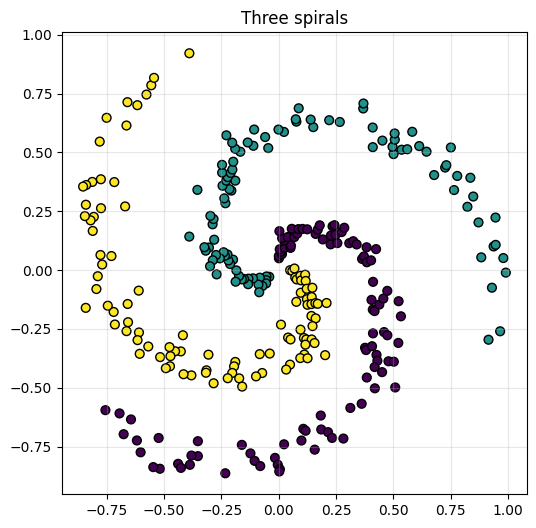

In [4]:
def make_spirals(n_per_class=100, n_classes=3, noise=0.2, seed=0):
    rng = np.random.default_rng(seed)
    X = np.zeros((n_per_class * n_classes, 2))
    y = np.zeros(n_per_class * n_classes, dtype=int)
    for c in range(n_classes):
        idx = slice(n_per_class * c, n_per_class * (c + 1))
        radius = np.linspace(0.05, 1, n_per_class)
        angle = np.linspace(4 * c, 4 * (c + 1), n_per_class) + rng.normal(0, noise, n_per_class)
        X[idx] = np.c_[radius * np.sin(angle), radius * np.cos(angle)]
        y[idx] = c
    return X, y

X_spiral, y_spiral = make_spirals()
Y_spiral = np.eye(3)[y_spiral]          # one-hot matrix Y (n x K)

plt.figure(figsize=(6, 6))
plt.scatter(X_spiral[:, 0], X_spiral[:, 1], c=y_spiral, cmap='viridis', edgecolor='k', s=40)
plt.title('Three spirals')
plt.grid(True, alpha=0.3)
plt.show()

In [5]:
def init_params(n_features, n_hidden, n_classes, seed=0):
    rng = np.random.default_rng(seed)
    return [
        rng.normal(0, 0.5, (n_features, n_hidden)),   # W_h
        np.zeros((1, n_hidden)),                      # b_h
        rng.normal(0, 0.5, (n_hidden, n_classes)),    # W_o
        np.zeros((1, n_classes)),                     # b_o
    ]

def tanh_prime(H):
    return 1 - np.tanh(H) ** 2

activations = {
    "relu": (relu, relu_prime, torch.relu),
    "tanh": (np.tanh, tanh_prime, torch.tanh),
}

params_spiral = init_params(n_features=2, n_hidden=16, n_classes=3)

### Training with the derived gradients

Now we train the network with plain full-batch gradient descent using only the gradients given above (they are checked against PyTorch's automatic differentiation in the [optional chapter](03-07-ANN-Multiclass-Derivatives-Optional.ipynb)).

relu: final loss 0.0152, training accuracy 1.000


tanh: final loss 0.0135, training accuracy 1.000


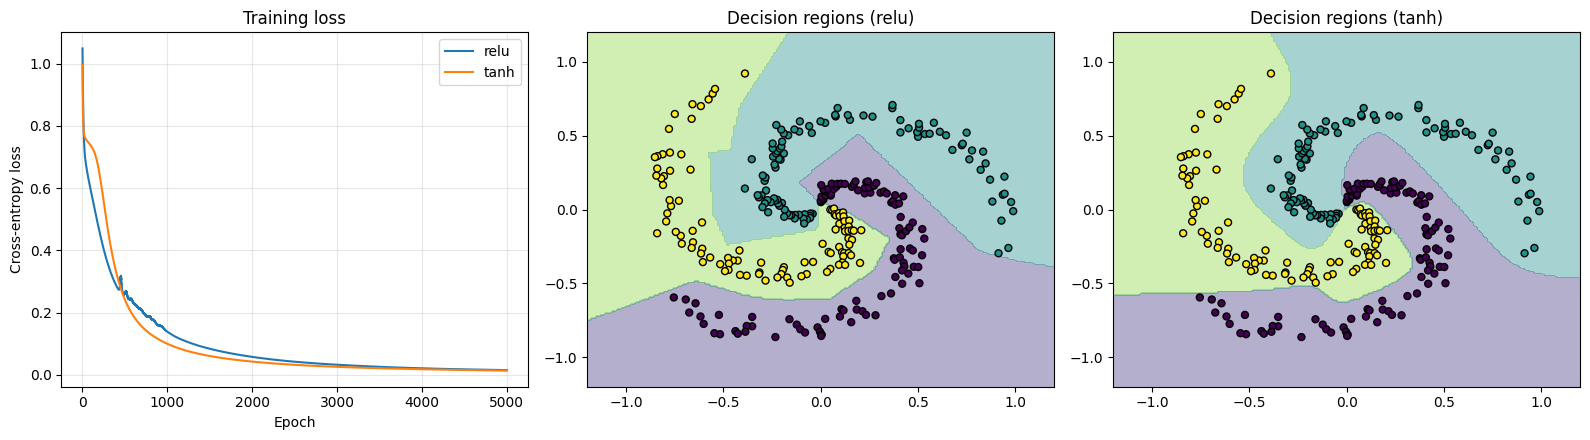

In [6]:
def train(X, Y, params, activation, activation_prime, learning_rate=0.5, epochs=5000):
    params = [p.copy() for p in params]
    losses = []
    for epoch in range(epochs):
        grads = gradients(X, Y, params, activation, activation_prime)
        for param, grad in zip(params, grads):
            param -= learning_rate * grad            # theta <- theta - eta * dL/dtheta
        losses.append(cross_entropy(Y, forward(X, params, activation)[2]))
    return params, losses

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

xx_s, yy_s = np.meshgrid(np.linspace(-1.2, 1.2, 200), np.linspace(-1.2, 1.2, 200))
grid_s = np.c_[xx_s.ravel(), yy_s.ravel()]

for ax, (name, (act, act_prime, _)) in zip(axes[1:], activations.items()):
    trained, losses = train(X_spiral, Y_spiral, params_spiral, act, act_prime)
    axes[0].plot(losses, label=name)

    accuracy = (forward(X_spiral, trained, act)[2].argmax(axis=1) == y_spiral).mean()
    print(f"{name}: final loss {losses[-1]:.4f}, training accuracy {accuracy:.3f}")

    predicted_class = forward(grid_s, trained, act)[2].argmax(axis=1).reshape(xx_s.shape)
    ax.contourf(xx_s, yy_s, predicted_class, levels=[-0.5, 0.5, 1.5, 2.5], cmap='viridis', alpha=0.4)
    ax.scatter(X_spiral[:, 0], X_spiral[:, 1], c=y_spiral, cmap='viridis', edgecolor='k', s=25)
    ax.set_title(f'Decision regions ({name})')

axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Cross-entropy loss')
axes[0].set_title('Training loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### The same network in PyTorch

In PyTorch the network is a sequence of layers. The last layer outputs the logits and `nn.CrossEntropyLoss` applies the softmax internally (and expects the class indices instead of the one-hot matrix). To see that PyTorch does exactly what we derived, we copy our initial parameters into the layers (the weight of an `nn.Linear(in, out)` layer has shape `(out, in)`, the transpose of our $W$), train with plain gradient descent and the same learning rate, and compare the result with the NumPy network.

In [7]:
trained_np, losses_np = train(X_spiral, Y_spiral, params_spiral, relu, relu_prime)

model = nn.Sequential(nn.Linear(2, 16), nn.ReLU(), nn.Linear(16, 3)).double()

with torch.no_grad():
    W_h0, b_h0, W_o0, b_o0 = params_spiral
    model[0].weight.copy_(torch.tensor(W_h0.T))
    model[0].bias.copy_(torch.tensor(b_h0.ravel()))
    model[2].weight.copy_(torch.tensor(W_o0.T))
    model[2].bias.copy_(torch.tensor(b_o0.ravel()))

criterion = nn.CrossEntropyLoss()                     # averages over the observations
optimizer = torch.optim.SGD(model.parameters(), lr=0.5)

X_tensor = torch.tensor(X_spiral)
labels_tensor = torch.tensor(y_spiral)

for epoch in range(5000):
    loss = criterion(model(X_tensor), labels_tensor)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

print(f"Final loss: PyTorch {loss.item():.6f}, NumPy {losses_np[-1]:.6f}")
print("Largest difference in W_h:", np.abs(model[0].weight.detach().numpy().T - trained_np[0]).max())
print("Largest difference in W_o:", np.abs(model[2].weight.detach().numpy().T - trained_np[2]).max())

Final loss: PyTorch 0.015157, NumPy 0.015152
Largest difference in W_h: 3.197442310920451e-14
Largest difference in W_o: 5.084821452783217e-14


## Application: the Bigram Model as a Softmax Network

In the [first chapter](03-02-ANN-Bigram-Motivation.ipynb) we estimated the probability of the next word by counting. Predicting the next word is a classification problem with $K = V$ classes (the words of the vocabulary), so we can learn the probabilities with a softmax network. The input is the current word, represented by a one-hot row vector $x$ of length $V$. Let the vocabulary be {Alice, beginning, get, tired, to, very, was} and consider the training sample **Alice was**:

$$
x_{Alice} = \begin{bmatrix} 1 & 0 & 0 & 0 & 0 & 0 & 0 \end{bmatrix}
\qquad
y_{was} = \begin{bmatrix} 0 & 0 & 0 & 0 & 0 & 0 & 1 \end{bmatrix}
$$

The model returns a vector of $V$ probabilities for the next word, for example $\hat{y}_{Alice} = \begin{bmatrix} 0.02 & 0.03 & 0.05 & 0.05 & 0.02 & 0.03 & 0.80 \end{bmatrix}$, and the cross-entropy loss of this sample is $-\log 0.80$.

**Without a hidden layer** the logits are $o = x W + b$ with a $V \times V$ weight matrix. Multiplying the one-hot vector with $W$ simply selects the **row** of $W$ that belongs to the current word, so each row of $W$ (plus the bias) holds the logits for the words that follow it:

$$
o = x_{Alice} W + b =
\begin{bmatrix} 1 & 0 & 0 & 0 & 0 \end{bmatrix}
\begin{bmatrix}
w_{11} & w_{12} & w_{13} & w_{14} & w_{15} \\
w_{21} & w_{22} & w_{23} & w_{24} & w_{25} \\
\vdots & & & & \vdots \\
w_{51} & w_{52} & w_{53} & w_{54} & w_{55}
\end{bmatrix}
+ \begin{bmatrix} b_1 & b_2 & b_3 & b_4 & b_5 \end{bmatrix}
= \begin{bmatrix} w_{11} + b_1 & w_{12} + b_2 & \cdots & w_{15} + b_5 \end{bmatrix}
$$

(shown for a vocabulary of five words). The cross-entropy loss is minimized when each row of the predicted probabilities equals the relative frequencies of the following words, i.e. exactly the counting estimates of the bigram model. The minimum of the loss is the average entropy of the bigram table.

**With a hidden layer** of width $d \ll V$ the model is $\hat{y} = \text{softmax}\big( \varphi(x W_h + b_h) W_o + b_o \big)$. Since $x$ is one-hot, $x W_h$ is the row of $W_h$ that belongs to the current word: a dense vector of length $d$, the **word embedding**. The probabilities of the next word are computed from this vector alone. Here we use the identity as the activation $\varphi$ (a *linear* hidden layer, as in word2vec); Bengio et al. [@BENGIO2003NeuralProbabilisticLanguage] used a tanh hidden layer. The model has $2Vd$ parameters instead of $V^2$.

The code trains both models on two sentences of *Alice's Adventures in Wonderland* and compares the learned probabilities with the counting estimates.

In [8]:
alice_text = """
Alice was beginning to get very tired of sitting by her sister on the
bank, and of having nothing to do. Once or twice she had peeped into the book her
sister was reading, but it had no pictures or conversations in it.
"""

import re
tokens = re.findall(r"[a-z']+", alice_text.lower())

vocab = sorted(set(tokens))
vocab_size = len(vocab)
word_to_idx = {word: idx for idx, word in enumerate(vocab)}
idx_to_word = {idx: word for word, idx in word_to_idx.items()}

print(f"Vocabulary size: {vocab_size}")

# Bigrams: (current word, next word)
bigrams = list(zip(tokens[:-1], tokens[1:]))
print(f"Number of bigrams: {len(bigrams)}")

# Input: one-hot row vectors, target: index of the next word
X_bigram = torch.eye(vocab_size)[[word_to_idx[current] for current, _ in bigrams]]
y_bigram = torch.tensor([word_to_idx[following] for _, following in bigrams])

print("X_bigram shape:", X_bigram.shape, " y_bigram shape:", y_bigram.shape)

Vocabulary size: 34
Number of bigrams: 42
X_bigram shape: torch.Size([42, 34])  y_bigram shape: torch.Size([42])


The counting estimates (the maximum likelihood bigram probabilities) serve as the benchmark:

In [9]:
counts = np.zeros((vocab_size, vocab_size))
for current, following in bigrams:
    counts[word_to_idx[current], word_to_idx[following]] += 1

row_totals = counts.sum(axis=1, keepdims=True)
count_probs = np.divide(counts, row_totals, out=np.zeros_like(counts), where=row_totals > 0)

# Average entropy of the bigram table over the observed bigrams = the smallest possible cross-entropy loss
minimum_loss = -np.mean([np.log(count_probs[word_to_idx[current], word_to_idx[following]])
                         for current, following in bigrams])
print(f"Smallest possible cross-entropy loss: {minimum_loss:.4f}")

Smallest possible cross-entropy loss: 0.2310


In [10]:
def fit(model, epochs, learning_rate=0.05):
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    for epoch in range(epochs):
        loss = criterion(model(X_bigram), y_bigram)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    return loss.item()

# Without a hidden layer: V x V logits (the model returns logits, the softmax is inside the loss)
torch.manual_seed(0)
bigram_model = nn.Linear(vocab_size, vocab_size)
print(f"No hidden layer:   loss {fit(bigram_model, epochs=1000):.4f}")

# With a (linear) hidden layer of width d: the weights of the first layer are the word embeddings
embedding_size = 8
torch.manual_seed(0)
bigram_model_hidden = nn.Sequential(
    nn.Linear(vocab_size, embedding_size, bias=False),
    nn.Linear(embedding_size, vocab_size),
)
print(f"Hidden layer d={embedding_size}: loss {fit(bigram_model_hidden, epochs=2000):.4f}")

n_parameters = lambda model: sum(p.numel() for p in model.parameters())
print("Parameters:", n_parameters(bigram_model), "vs", n_parameters(bigram_model_hidden))

No hidden layer:   loss 0.2330


Hidden layer d=8: loss 0.2311
Parameters: 1190 vs 578


Both models recover the counting estimates. For example, "of" is followed once by "sitting" and once by "having", and "sister" is followed once by "on" and once by "was":

In [11]:
def next_word_probs(model, word):
    with torch.no_grad():
        logits = model(torch.eye(vocab_size)[word_to_idx[word]])
        return torch.softmax(logits, dim=0).numpy()

for word in ["alice", "of", "sister"]:
    top = np.argsort(-count_probs[word_to_idx[word]])[:3]
    print(f"After '{word}':")
    for j in top:
        print(f"  {idx_to_word[j]:10s} counting {count_probs[word_to_idx[word], j]:.2f}"
              f"   no hidden layer {next_word_probs(bigram_model, word)[j]:.2f}"
              f"   hidden layer {next_word_probs(bigram_model_hidden, word)[j]:.2f}")

After 'alice':
  was        counting 1.00   no hidden layer 1.00   hidden layer 1.00
  alice      counting 0.00   no hidden layer 0.00   hidden layer 0.00
  bank       counting 0.00   no hidden layer 0.00   hidden layer 0.00
After 'of':
  having     counting 0.50   no hidden layer 0.50   hidden layer 0.51
  sitting    counting 0.50   no hidden layer 0.50   hidden layer 0.49
  bank       counting 0.00   no hidden layer 0.00   hidden layer 0.00
After 'sister':
  on         counting 0.50   no hidden layer 0.50   hidden layer 0.50
  was        counting 0.50   no hidden layer 0.50   hidden layer 0.50
  bank       counting 0.00   no hidden layer 0.00   hidden layer 0.00


The rows of the first weight matrix are the word vectors (embeddings). They are learned only from the requirement that they predict the next word well. In the chapter on Word2Vec we use the same idea with larger corpora and a different prediction task.

In [12]:
# PyTorch stores the weight as (d x V), i.e. the transpose of W_h (V x d)
embeddings = bigram_model_hidden[0].weight.detach().numpy().T

print("Embedding matrix shape:", embeddings.shape)
print("Embedding of 'alice':", embeddings[word_to_idx['alice']].round(2))

Embedding matrix shape: (34, 8)
Embedding of 'alice': [-0.09 -1.96 -1.33 -0.81 -1.47  2.44 -1.68 -2.27]


In [13]:
# Generate text by always choosing the most likely next word
def generate_sentence(start_word, model, length=8):
    sentence = [start_word]
    for _ in range(length - 1):
        probs = next_word_probs(model, sentence[-1])
        sentence.append(idx_to_word[int(np.argmax(probs))])
    return " ".join(sentence)

print(generate_sentence("alice", bigram_model))

alice was reading but it had no pictures
